<a href="https://colab.research.google.com/github/Martazzz/dropout_rate_academic_success/blob/main/notebooks/02_blocks_A_B.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Style and palette
---
Common style for the whole project: chart appearance and the order of the categories, so that all the notebooks produce consistent charts.

In [51]:
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams.update(
    {
        "figure.figsize": (9, 5),
        "axes.titlesize": 14,
        "axes.titleweight": "bold",
        "axes.labelsize": 12,
        "xtick.labelsize": 10,
        "ytick.labelsize": 10,
    }
)

OUTCOME_ORDER = ["Dropout", "Enrolled", "Graduate"]
OUTCOME_PALETTE = {"Dropout": "#9b4141", "Enrolled": "#b8b8b8", "Graduate": "#298c8c"}
BAR_COLOR = "#0072B2"
DROPOUT_COLOR = "#9b4141"

os.makedirs("figures", exist_ok=True)

ORDER = {
    "Target": OUTCOME_ORDER,
    "Gender": ["Female", "Male"],
    "Displaced": ["No", "Yes"],
    "Debtor": ["No", "Yes"],
    "Tuition_Up_To_Date": ["No", "Yes"],
    "Scholarship_Holder": ["No", "Yes"],
    "Daytime_Evening": ["Daytime", "Evening"],
    "Marital_Group": ["Single", "Not single"],
    "Age_Group": ["17-19", "20-24", "25-29", "30+"],
    "Admission_Grade_Band": ["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"],
    "Parent_Education": ["Basic", "Secondary", "Higher", "Unknown"],
    "Application_Order_Group": ["0-1", "2", "3+"],
    "Application_Mode_Group": [
        "General contingent",
        "Over 23 years old",
        "Transfer or change",
        "Prior diploma holder",
        "Special or other",
    ],
    "Passed_None_1st": ["No", "Yes"],
    "Passed_None_2nd": ["No", "Yes"],
}


def apply_order(df):
    df = df.copy()
    for col, cats in ORDER.items():
        if col in df.columns:
            df[col] = pd.Categorical(df[col], categories=cats, ordered=True)
    return df

# Function definition
---
Defining the main functions to test the correlations between variables and their effects.

In [52]:
data = apply_order(pd.read_csv("student_dropout_cleaned.csv", sep=';'))

# to see the effect of the correlation between two categorical variables
def cramers_v(table):
    chi2 = stats.chi2_contingency(table)[0]
    n = table.values.sum()
    return np.sqrt(chi2 / (n * (min(table.shape) - 1)))

# defining the format of the p value (if it too small it's set to 0.001)
def format_p(p):
    return "p < 0.001" if p < 0.001 else f"p = {p:.3f}"

def chi2_test(df, col, target="Target"):
    table = pd.crosstab(df[col], df[target])
    chi2, p, dof, _ = stats.chi2_contingency(table)
    print(f"Chi-square test, {col} vs {target}: chi2 = {chi2:.1f}, dof = {dof}, {format_p(p)}, "
          f"Cramer's V = {cramers_v(table):.2f}")
    return table

# it computes the dropout rate for the category
def dropout_rates(col):
    out = data.groupby(col, observed=True)["Dropout_Binary"].agg(["mean", "count"])
    out["mean"] = (out["mean"] * 100).round(1)
    out.columns = ["dropout_rate_%", "n"]
    return out


def kruskal_test(df, col, target="Target"):
    groups = [df.loc[df[target] == o, col].dropna() for o in OUTCOME_ORDER]
    h, p = stats.kruskal(*groups)
    n = sum(len(g) for g in groups)
    eps2 = h / (n - 1)
    print(f"Kruskal-Wallis test, {col} by {target}: H = {h:.1f}, {format_p(p)}, "
          f"epsilon squared = {eps2:.2f}, n = {n}")


def spearman_test(df, col, target="Dropout_Binary"):
    sub = df[[col, target]].dropna() #it removes the missing values rows
    rho, p = stats.spearmanr(sub[col], sub[target])
    print(f"Spearman correlation, {col} vs {target}: rho = {rho:.2f}, {format_p(p)}, n = {len(sub)}")


def plot_outcome_composition(ax, col):
    pct = pd.crosstab(data[col], data["Target"], normalize="index")[OUTCOME_ORDER] * 100
    n = data[col].value_counts()
    pct.plot(kind="barh", stacked=True, width=0.7, ax=ax,
             color=[OUTCOME_PALETTE[o] for o in OUTCOME_ORDER])
    for container in ax.containers:
        ax.bar_label(container, fmt="%.0f%%", label_type="center", color="white", fontsize=10)
    ax.set_yticklabels([f"{c} (n={n[c]})" for c in pct.index], rotation=0)
    ax.invert_yaxis()
    ax.set_xlim(0, 100)
    ax.set_xlabel("Percentage of students (%)")
    ax.set_ylabel("")
    ax.legend(title="Outcome", loc="upper left", bbox_to_anchor=(1.01, 1))
    ax.grid(axis="y", visible=False)


def composition_figure(col, title, filename, height=3.5):
    fig, ax = plt.subplots(figsize=(10, height))
    plot_outcome_composition(ax, col)
    ax.set_title(title)
    plt.tight_layout()
    plt.savefig(f"figures/{filename}.png", dpi=200, bbox_inches="tight")
    plt.show()

# **Block A: demographics**
---
**Question**: do the demographic features of students (gender, age, marital status, displaced) go together with different outcomes?

**Method**: for each variable we compare the share of dropout, enrolled and graduate students using chi-square test, Cramer's V and Kruskal-Wallis test (for age).

## A1. Gender and outcome
---
**Question**: is gender associated with the outcome?

**Method**: stacked bar chart and chi-square test with Cramer's V.

Chi-square test, Gender vs Target: chi2 = 233.3, dof = 2, p < 0.001, Cramer's V = 0.23
        dropout_rate_%     n
Gender                      
Female            25.1  2868
Male              45.1  1556


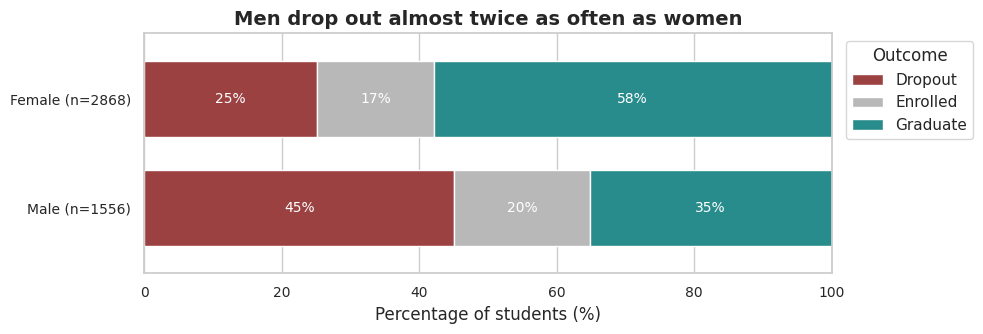

In [53]:
table = chi2_test(data, "Gender")
print(dropout_rates("Gender"))
composition_figure("Gender", "Men drop out almost twice as often as women", "blockA_gender_outcome")

Men drop out much more often than women (45% vs 25%), and only 35% of men graduate against 58% of women. The association is significant but weak (V = 0.23), and it may partly reflect the course.

## A2. Age at enrollment and outcome
---
**Question**: is the age at enrollment associated with the outcome?

**Method**: stacked bar chart by age group, boxplot of age by outcome, chi-square test on the age groups and Kruskal-Wallis test on the age in years.


Chi-square test, Age_Group vs Target: chi2 = 452.0, dof = 6, p < 0.001, Cramer's V = 0.23
           dropout_rate_%     n
Age_Group                      
17-19                21.0  1952
20-24                28.6  1334
25-29                57.6   427
30+                  54.1   711
Kruskal-Wallis test, Age_At_Enrollment by Target: H = 375.1, p < 0.001, epsilon squared = 0.08, n = 4424
Target
Dropout     23.0
Enrolled    20.0
Graduate    19.0
Name: Age_At_Enrollment, dtype: float64


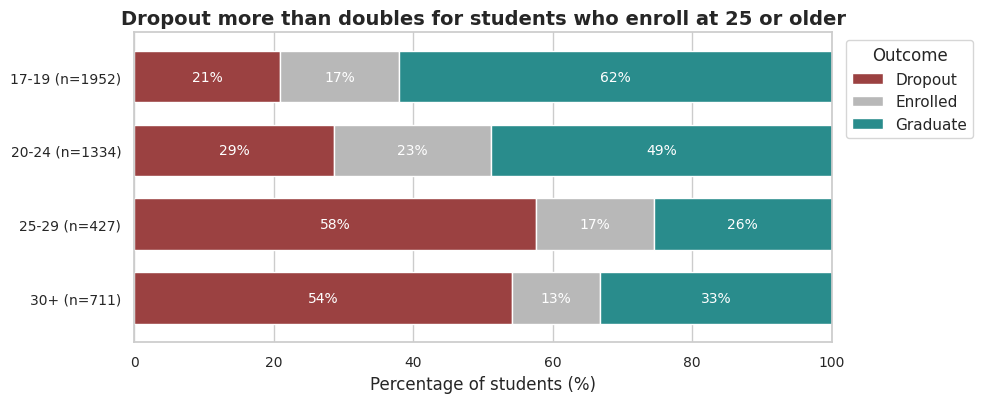

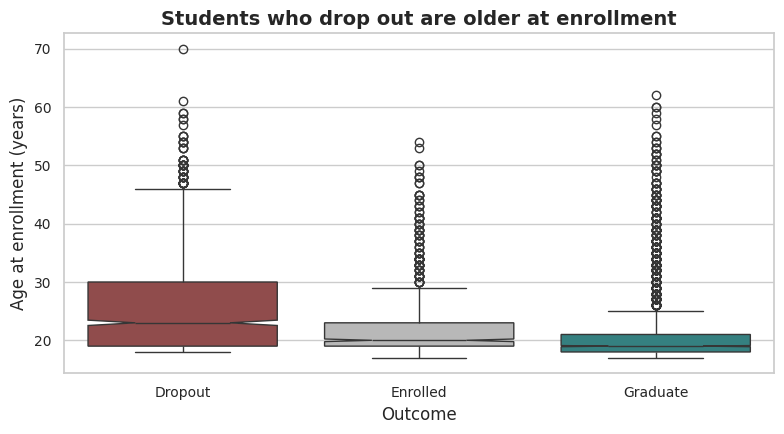

In [54]:
table = chi2_test(data, "Age_Group")
print(dropout_rates("Age_Group"))
kruskal_test(data, "Age_At_Enrollment")
print(data.groupby("Target", observed=True)["Age_At_Enrollment"].median())
composition_figure("Age_Group", "Dropout more than doubles for students who enroll at 25 or older",
                   "blockA_age_outcome", 4.2)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=data, x="Target", y="Age_At_Enrollment", hue="Target", order=OUTCOME_ORDER, notch=True,
            palette=OUTCOME_PALETTE, legend=False, ax=ax)
ax.set_title("Students who drop out are older at enrollment")
ax.set_xlabel("Outcome")
ax.set_ylabel("Age at enrollment (years)")
plt.tight_layout()
plt.savefig("figures/blockA_age_boxplot.png", dpi=200, bbox_inches="tight")
plt.show()

The median age is 23 for dropouts and 19 for graduates. The effect is weak on age groups (V = 0.23) and medium on age in years (epsilon squared = 0.08).

## A3. Marital status and outcome
---
**Question**: do students who are not single have different outcomes?

**Method**: stacked bar chart and chi-square test with Cramér's V.

Chi-square test, Marital_Group vs Target: chi2 = 57.5, dof = 2, p < 0.001, Cramer's V = 0.11
               dropout_rate_%     n
Marital_Group                      
Single                   30.2  3919
Not single               46.9   505


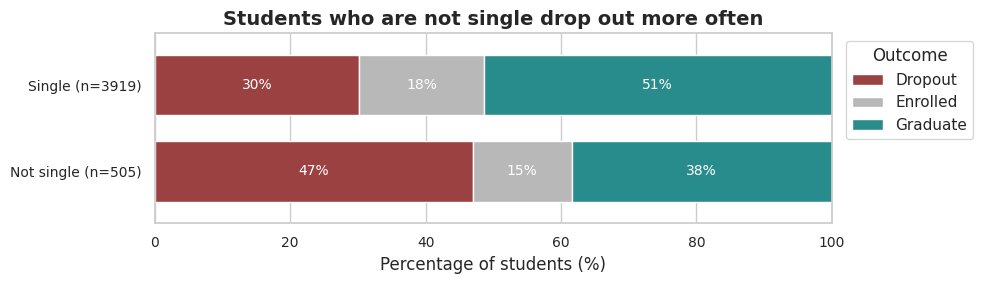

In [55]:
table = chi2_test(data, "Marital_Group")
print(dropout_rates("Marital_Group"))
composition_figure("Marital_Group", "Students who are not single drop out more often",
                   "blockA_marital_outcome", 3)

Students who are not single drop out more (47% vs 30%). The effect is weak (V = 0.11), and the group is small (n = 505).

## A4. Displaced students and outcome
---
**Question**: do displaced students have different outcomes?

**Method**: stacked bar chart and chi-square test with Cramér's V.

Chi-square test, Displaced vs Target: chi2 = 57.8, dof = 2, p < 0.001, Cramer's V = 0.11
           dropout_rate_%     n
Displaced                      
No                   37.6  1998
Yes                  27.6  2426


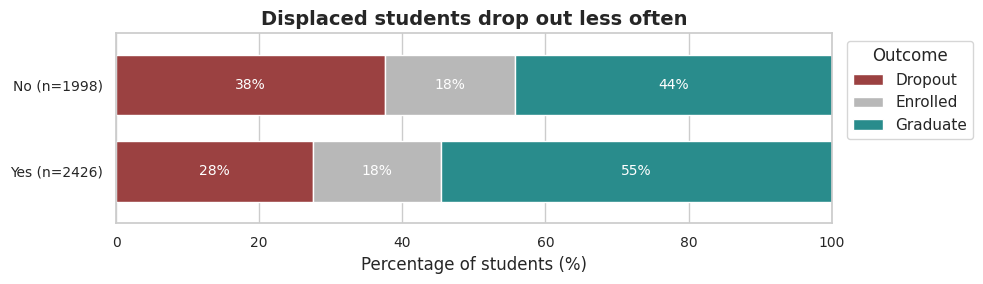

In [56]:
table = chi2_test(data, "Displaced")
print(dropout_rates("Displaced"))
composition_figure("Displaced", "Displaced students drop out less often", "blockA_displaced_outcome", 3)

Displaced students drop out less (28% vs 38%). The effect is weak (V = 0.11).

# **Block B: economic situation**
---
**Question**: is the economic situation of students (scholarship, debts, tuition fees, parents' education) associated with the outcome?

**Method**: same as block A. Tuition fees and debts may be partly a consequence of dropping out, not only a cause.

## B1. Scholarship and outcome
---
**Question**: do scholarship holders drop out less?

**Method**: stacked bar chart and chi-square test with Cramér's V. A scholarship may depend on merit, so it may also reflect academic performance.

Chi-square test, Scholarship_Holder vs Target: chi2 = 409.9, dof = 2, p < 0.001, Cramer's V = 0.30
                    dropout_rate_%     n
Scholarship_Holder                      
No                            38.7  3325
Yes                           12.2  1099


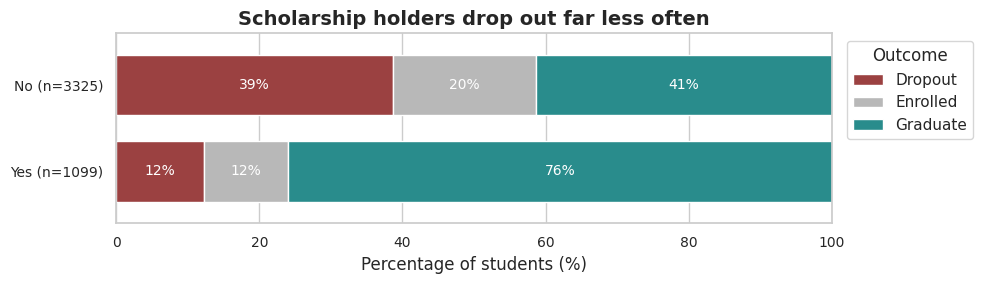

In [57]:
table = chi2_test(data, "Scholarship_Holder")
print(dropout_rates("Scholarship_Holder"))
composition_figure("Scholarship_Holder", "Scholarship holders drop out far less often",
                   "blockB_scholarship_outcome", 3)

Scholarship holders drop out less (12% vs 39%), and 76% of them graduate. The effect is between weak and moderate (V = 0.30). A scholarship may depend on merit, so it can also reflect performance.

## B2. Debtors and outcome
---
**Question**: do students registered as debtors drop out more?

**Method**: stacked bar chart and chi-square test with Cramér's V.

Chi-square test, Debtor vs Target: chi2 = 259.3, dof = 2, p < 0.001, Cramer's V = 0.24
        dropout_rate_%     n
Debtor                      
No                28.3  3921
Yes               62.0   503


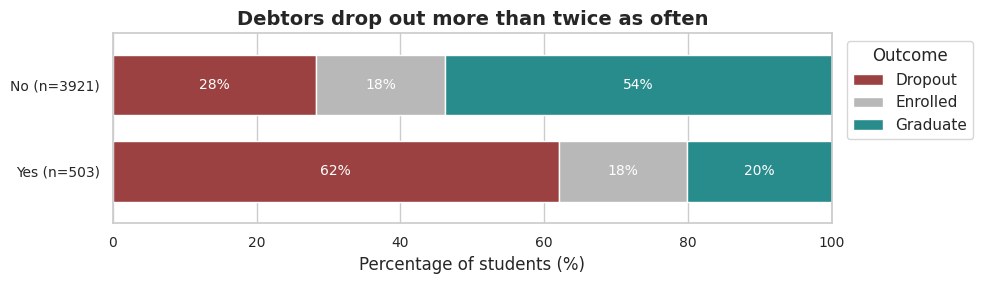

In [58]:
table = chi2_test(data, "Debtor")
print(dropout_rates("Debtor"))
composition_figure("Debtor", "Debtors drop out more than twice as often", "blockB_debtor_outcome", 3)

Debtors drop out more than twice as often (62% vs 28%). The effect is weak (V = 0.24).

## B3. Tuition fees and outcome
---
**Question**: do students whose tuition fees are not up to date drop out more?

**Method**: stacked bar chart and chi-square test with Cramér's V.

**Note:** this is the strongest association of the block, but someone who leaves may stop paying, so it is partly a consequence of dropout.

Chi-square test, Tuition_Up_To_Date vs Target: chi2 = 823.6, dof = 2, p < 0.001, Cramer's V = 0.43
                    dropout_rate_%     n
Tuition_Up_To_Date                      
No                            86.6   528
Yes                           24.7  3896


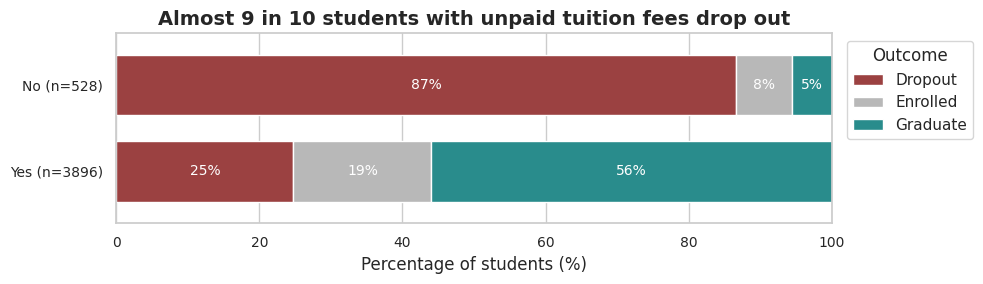

In [59]:
table = chi2_test(data, "Tuition_Up_To_Date")
print(dropout_rates("Tuition_Up_To_Date"))
composition_figure("Tuition_Up_To_Date", "Almost 9 in 10 students with unpaid tuition fees drop out",
                   "blockB_tuition_outcome", 3)

87% of students with fees not up to date drop out, against 25% of the others. It is the strongest association (V = 0.43), but it is partly a consequence of dropout, since someone who leaves may stop paying.

## B4. Parents' education and outcome
---
**Question:** is the education level of the parents associated with the outcome?

**Method:** stacked bar chart and chi-square test with Cramér's V, with and without the "Unknown" group.

Chi-square test, Parent_Education vs Target: chi2 = 104.7, dof = 6, p < 0.001, Cramer's V = 0.11
                  dropout_rate_%     n
Parent_Education                      
Basic                       31.7  2220
Secondary                   30.1  1311
Higher                      31.4   793
Unknown                     74.0   100


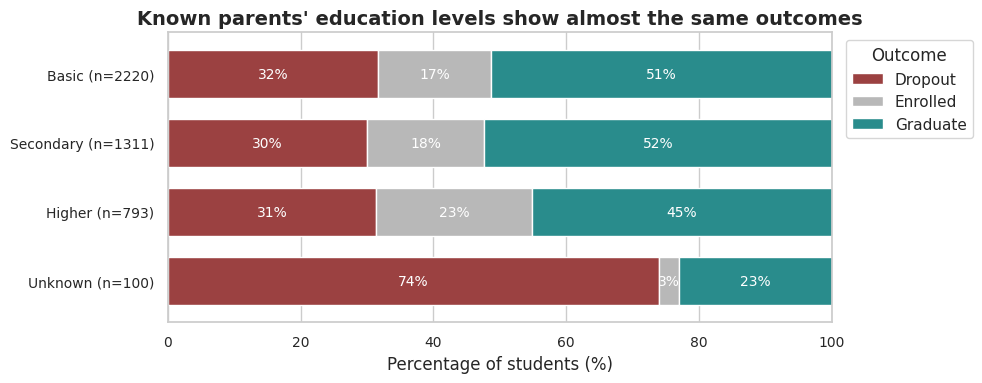

Chi-square test, Parent_Education vs Target: chi2 = 20.9, dof = 4, p < 0.001, Cramer's V = 0.05


In [60]:
table = chi2_test(data, "Parent_Education")
print(dropout_rates("Parent_Education"))
composition_figure("Parent_Education", "Known parents' education levels show almost the same outcomes",
                   "blockB_parent_education_outcome", 4)

known = data[data["Parent_Education"] != "Unknown"].copy()
known["Parent_Education"] = known["Parent_Education"].cat.remove_unused_categories()
table_known = chi2_test(known, "Parent_Education")

The dropout rate is practically the same for Basic, Secondary and Higher (32%, 30%, 31%).

## B5. Financial risk and outcome
---
**Question:** does the dropout risk grow with the number of financial risk factors (debtor, tuition fees not up to date, no scholarship)?

**Method:** bar chart of the dropout rate for each level of risk (0-3), chi-square test with Cramér's V and Spearman correlation between risk and dropout.

Chi-square test, Financial_Risk vs Target: chi2 = 1038.1, dof = 6, p < 0.001, Cramer's V = 0.34
                dropout_rate_%     n
Financial_Risk                      
0                          9.3   992
1                         29.3  2731
2                         69.2   478
3                         88.8   223
Spearman correlation, Financial_Risk vs Dropout_Binary: rho = 0.42, p < 0.001, n = 4424


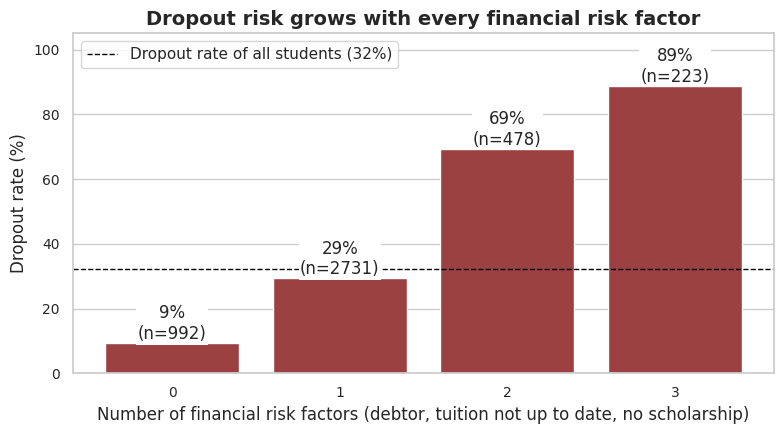

In [61]:
table = chi2_test(data, "Financial_Risk")
print(dropout_rates("Financial_Risk"))
spearman_test(data, "Financial_Risk")

rates = data.groupby("Financial_Risk")["Dropout_Binary"].agg(["mean", "count"])
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(rates.index.astype(str), rates["mean"] * 100, color=DROPOUT_COLOR)
ax.bar_label(bars, labels=[f"{m*100:.0f}%\n(n={c})" for m, c in zip(rates["mean"], rates["count"])],
             bbox=dict(facecolor="white", edgecolor="none", pad=1))
ax.axhline(data["Dropout_Binary"].mean() * 100, color="black", linestyle="--", linewidth=1,
           label="Dropout rate of all students (32%)")
ax.legend(loc="upper left")
ax.set_ylim(0, 105)
ax.set_xlabel("Number of financial risk factors (debtor, tuition not up to date, no scholarship)")
ax.set_ylabel("Dropout rate (%)")
ax.set_title("Dropout risk grows with every financial risk factor")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.savefig("figures/blockB_financial_risk_dropout.png", dpi=200, bbox_inches="tight")
plt.show()

The dropout rate grows with every risk factor: 9%, 29%, 69%, 89% for 0, 1, 2, 3 factors. The effect is moderate (V = 0.34, Spearman rho = 0.42).